# E-Commerce Review Analytics — Flipkart Product Reviews

**CBS3009 — Social, Text and Media Analytics** · Course Project

This notebook reproduces the complete analysis end to end, from the raw Kaggle CSV to the final
validated results. *Kernel → Restart and Run All* regenerates every number quoted in the report.

**Three analytical components:**

| # | Component | Method | Evaluated by |
|---|---|---|---|
| 1 | Sentiment classification | TF-IDF + 4 classifiers | Accuracy, precision, recall, weighted & macro F1 |
| 2 | Topic discovery | LDA (6 topics) | UMass coherence, topic–sentiment crosstab |
| 3 | Low-information review detection | K-Means on behavioural features | Silhouette **and** 200 blind labelled reviews |

Component 3 is validated against independent external labels rather than reported on internal
metrics alone, which is the main methodological contribution of this project.

**Label provenance:** those labels were produced by an LLM applying a pre-registered written
criterion, not by a human annotator. Section 8 explains what that does and does not support.

---
## 1. Introduction

### Problem statement

E-commerce platforms accumulate review volumes far beyond what any person can read. For Flipkart
alone this dataset holds 189,874 reviews across 812 products. Star ratings compress all of that
into a single number, which hides *why* customers are satisfied or dissatisfied, and treats every
review as equally informative — including the thousands that say nothing more than "Good".

### Objectives

1. Classify review sentiment from text and compare multiple algorithms on equal terms.
2. Discover the latent themes customers actually write about, without pre-defining categories.
3. Identify reviews that carry little or no information, and **validate that identification
   against independent external labels**.
4. Combine the three to explain not just *what* customers feel, but *why*, and *how much of the
   review corpus is worth reading at all*.

### Analytical questions

- **AQ1.** How accurately can sentiment be predicted from review text, and which algorithm is
  best — and best *by which criterion*?
- **AQ2.** What themes dominate the reviews, and do any carry disproportionate negativity?
- **AQ3.** What share of reviews are low-information, and can an unsupervised method identify
  them reliably enough to agree with a human?

In [1]:
import warnings, re
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid')

RANDOM_STATE = 42

ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
RAW = ROOT / 'data' / 'raw' / 'flipkart_product.csv'
print('Project root:', ROOT)
print('Raw data exists:', RAW.exists())

Project root: C:\Users\HETARTH\OneDrive\Desktop\ASTAMA
Raw data exists: True


---
## 2. Dataset documentation

**Source:** [Flipkart Products Review Dataset](https://www.kaggle.com/datasets/mansithummar67/flipkart-product-review-dataset)
by Mansi Thummar, publicly released on Kaggle for research and education.

**Ethics note.** Only review text, star ratings, product names and prices are used. No personal
identifiers are present or used. No data was collected from Flipkart directly, so platform
scraping terms do not apply to this work. Live scraping was attempted during development and
deliberately abandoned — Flipkart's API gateway returns HTTP 403 to non-browser clients — and
using an approved public dataset was both the lower-risk and guideline-compliant choice.

**Encoding quirk.** The file must be read with `encoding='latin1'`; it contains non-UTF8 bytes
left over from the original scrape, visible as mojibake in currency symbols and emoji.

In [2]:
df_raw = pd.read_csv(RAW, encoding='latin1')
print(f'Raw shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns')
print(f'Unique products: {df_raw["ProductName"].nunique():,}')
df_raw.head(3)

Raw shape: 189,874 rows x 5 columns
Unique products: 812


,ProductName,Price,Rate,Review,Summary
0,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",5,Super!,Great cooler.. excellent air flow and for this...
1,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",5,Awesome,Best budget 2 fit cooler. Nice cooling
2,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",3,Fair,The quality is good but the power of air is de...


In [3]:
print('Columns and types:')
print(df_raw.dtypes.to_string())
print('\nMissing values per column:')
print(df_raw.isna().sum().to_string())
print('\nNote: Rate is object, not int -- some rows have product text leaked into')
print('the rating column from unescaped commas in the original scrape.')

Columns and types:
ProductName    str
Price          str
Rate           str
Review         str
Summary        str

Missing values per column:
ProductName     0
Price           1
Rate            1
Review          4
Summary        14

Note: Rate is object, not int -- some rows have product text leaked into
the rating column from unescaped commas in the original scrape.


---
## 3. Preprocessing

Each step below removes a specific, identified defect. Row counts are printed after every step so
the effect of each is auditable — a requirement of the project guidelines.

In [4]:
df = df_raw.copy()
log = []

# Step 1: coerce ratings to numeric and drop corrupted rows.
# Non-numeric Rate values come from unescaped commas breaking column alignment.
before = len(df)
df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')
df = df.dropna(subset=['Rate'])
df['Rate'] = df['Rate'].astype(int)
df = df[df['Rate'].between(1, 5)]
log.append(('1. Drop corrupted Rate values', before - len(df), len(df)))

# Step 2: drop rows with no review text -- nothing to analyse.
before = len(df)
df = df.dropna(subset=['Summary'])
log.append(('2. Drop missing Summary text', before - len(df), len(df)))

# Step 3: strip non-ASCII mojibake while preserving review content.
def clean_text(text):
    if pd.isna(text):
        return ''
    text = re.sub(r'[^\x00-\x7F]+', ' ', str(text))
    return re.sub(r'\s+', ' ', text).strip()

df['ProductName_clean'] = df['ProductName'].apply(clean_text)
df['Summary_clean'] = df['Summary'].apply(clean_text)
df['Review_clean'] = df['Review'].apply(clean_text)

# Step 4: parse price to integer ('??3,999' -> 3999).
df['Price_clean'] = df['Price'].apply(
    lambda p: int(re.sub(r'[^\d]', '', str(p))) if pd.notna(p)
    and re.sub(r'[^\d]', '', str(p)) else np.nan)
log.append(('3-4. Clean text and price (no rows dropped)', 0, len(df)))
print('Steps 1-4 complete.')

Steps 1-4 complete.


### Step 5: record text repetition *before* deduplication

This ordering matters and was a genuine bug during development. Step 6 removes duplicate reviews.
If repetition is counted *after* that removal, the count is 1 for almost every row and the feature
carries no signal — which silently disabled an entire feature of the clustering component.

The count is therefore taken here, before anything is dropped, and measured **across all
products** so that generic text copy-pasted over hundreds of listings is captured.

In [5]:
text_norm = df['Summary_clean'].str.lower().str.strip()
df['text_freq_global'] = text_norm.map(text_norm.value_counts())
df['text_freq_product'] = text_norm.groupby(
    [df['ProductName_clean'], text_norm]).transform('size')

print(f"Most repeated review text occurs {df['text_freq_global'].max():,} times")
print(f"Reviews sharing text with at least one other: "
      f"{(df['text_freq_global'] > 1).sum():,} "
      f"({100*(df['text_freq_global'] > 1).mean():.1f}%)")
print('\nTop repeated texts in the raw data:')
print(df[['Summary_clean', 'text_freq_global']]
      .drop_duplicates('Summary_clean').nlargest(6, 'text_freq_global')
      .to_string(index=False))

Most repeated review text occurs 15,818 times
Reviews sharing text with at least one other: 107,776 (56.8%)

Top repeated texts in the raw data:
Summary_clean  text_freq_global
         Good             15818
         good             15818
         GOOD             15818
         GooD             15818
         Nice              9049
         nice              9049


In [6]:
# Step 6: remove exact duplicate (product, review) pairs -- scraping artefacts.
before = len(df)
df = df.drop_duplicates(subset=['ProductName_clean', 'Summary_clean'])
log.append(('5-6. Drop exact duplicate reviews', before - len(df), len(df)))

# Step 7: derive the sentiment label from the star rating.
# NOTE: this is a standard mapping, but it means the classifiers learn to
# predict the STAR RATING from text, not human-judged sentiment. Stated as a
# limitation in section 10.
df['sentiment_label'] = df['Rate'].apply(
    lambda r: 'positive' if r >= 4 else ('neutral' if r == 3 else 'negative'))

df['word_count'] = df['Summary_clean'].apply(lambda x: len(x.split()))

print(pd.DataFrame(log, columns=['Step', 'Rows dropped', 'Rows remaining'])
      .to_string(index=False))
print(f'\nFinal cleaned dataset: {len(df):,} rows')
print('\nSentiment label distribution:')
print(df['sentiment_label'].value_counts().to_string())

                                       Step  Rows dropped  Rows remaining
              1. Drop corrupted Rate values             5          189869
               2. Drop missing Summary text            13          189856
3-4. Clean text and price (no rows dropped)             0          189856
          5-6. Drop exact duplicate reviews         57446          132410



Final cleaned dataset: 132,410 rows

Sentiment label distribution:
sentiment_label
positive    98170
negative    23207
neutral     11033


---
## 4. Exploratory data analysis

Two facts here shape every later decision: the corpus is heavily skewed toward positive ratings,
and most reviews are extremely short (median 5 words).

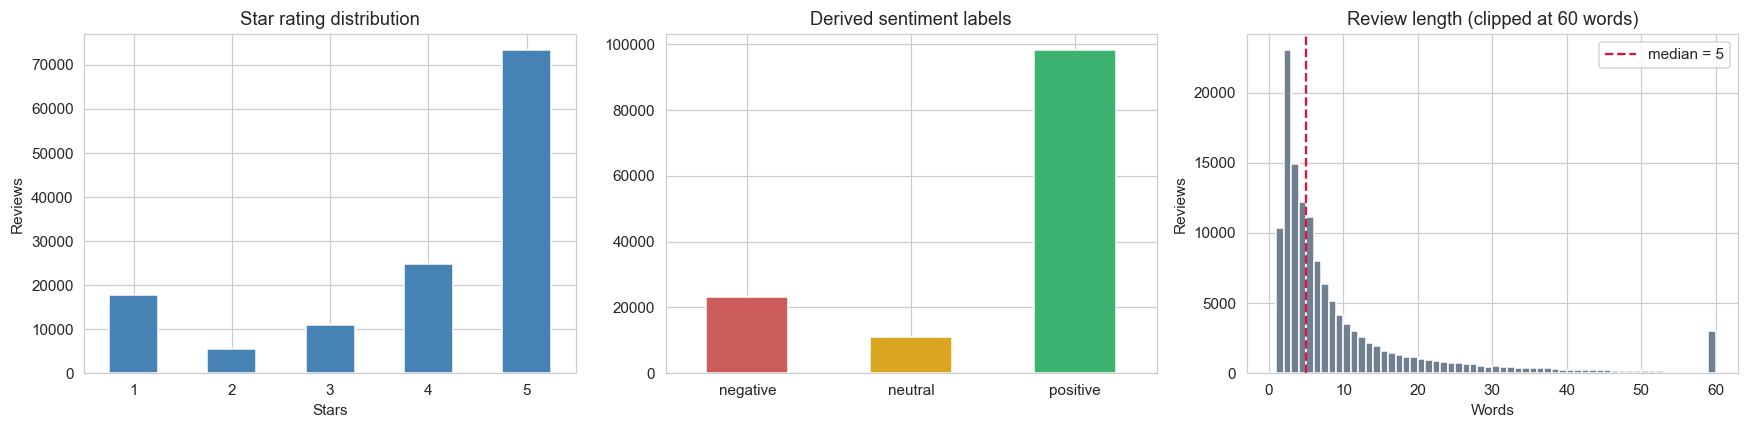

Class imbalance: positive is 74.1% of the data, neutral only 8.3%.
Review length: median 5 words, mean 10.1, max 109


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df['Rate'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Star rating distribution')
axes[0].set_xlabel('Stars'); axes[0].set_ylabel('Reviews'); axes[0].tick_params(axis='x', rotation=0)

order = ['negative', 'neutral', 'positive']
df['sentiment_label'].value_counts().reindex(order).plot(
    kind='bar', ax=axes[1], color=['indianred', 'goldenrod', 'mediumseagreen'])
axes[1].set_title('Derived sentiment labels')
axes[1].set_xlabel(''); axes[1].tick_params(axis='x', rotation=0)

axes[2].hist(df['word_count'].clip(upper=60), bins=60, color='slategrey')
axes[2].set_title('Review length (clipped at 60 words)')
axes[2].set_xlabel('Words'); axes[2].set_ylabel('Reviews')
axes[2].axvline(df['word_count'].median(), color='crimson', ls='--',
                label=f"median = {df['word_count'].median():.0f}")
axes[2].legend()

plt.tight_layout(); plt.show()

print(f"Class imbalance: positive is {100*(df.sentiment_label=='positive').mean():.1f}% "
      f"of the data, neutral only {100*(df.sentiment_label=='neutral').mean():.1f}%.")
print(f"Review length: median {df['word_count'].median():.0f} words, "
      f"mean {df['word_count'].mean():.1f}, max {df['word_count'].max()}")

---
## 5. Component 1 — Sentiment classification

**Feature representation: TF-IDF.** Chosen over raw counts because it down-weights terms that
appear in most reviews regardless of sentiment ("product", "good") and up-weights distinguishing
terms. Bigrams are included so negations like "not good" survive as units.

**Four classifiers are compared** — two generative (Multinomial NB, Complement NB), one tree-based
(Decision Tree), one discriminative linear (Logistic Regression).

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

df_clf = df[df['word_count'] >= 2].copy()
print(f'Reviews used (>=2 words): {len(df_clf):,}')

tfidf = TfidfVectorizer(max_features=5000, stop_words='english',
                        ngram_range=(1, 2), min_df=5)
X = tfidf.fit_transform(df_clf['Summary_clean'])
y = df_clf['sentiment_label']

positions = np.arange(X.shape[0])
X_train, X_test, y_train, y_test, pos_train, pos_test = train_test_split(
    X, y, positions, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(f'Train: {X_train.shape[0]:,}   Test: {X_test.shape[0]:,}   '
      f'Features: {X.shape[1]:,}')

Reviews used (>=2 words): 122,029


Train: 97,623   Test: 24,406   Features: 5,000


In [9]:
LABELS = ['negative', 'neutral', 'positive']
classifiers = {
    'Naive Bayes': MultinomialNB(),
    'Decision Tree': DecisionTreeClassifier(max_depth=30, class_weight='balanced',
                                            random_state=RANDOM_STATE),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced',
                                              random_state=RANDOM_STATE),
    'Complement NB': ComplementNB(),
}

results = {}
for name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)
    wp, wr, wf1, _ = precision_recall_fscore_support(
        y_test, pred, average='weighted', zero_division=0)
    per_class = precision_recall_fscore_support(
        y_test, pred, labels=LABELS, zero_division=0)[2]
    results[name] = {
        'pred': pred,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': wp, 'Recall': wr, 'F1': wf1,
        'Macro_F1': precision_recall_fscore_support(
            y_test, pred, average='macro', zero_division=0)[2],
        'Negative_F1': per_class[0],
        'Neutral_F1': per_class[1],
    }

comparison = pd.DataFrame(
    {n: {k: v for k, v in r.items() if k != 'pred'} for n, r in results.items()}).T
comparison.round(4)

,Accuracy,Precision,Recall,F1,Macro_F1,Negative_F1,Neutral_F1
Naive Bayes,0.8474,0.8187,0.8474,0.8222,0.6100,0.7385,0.1758
Decision Tree,0.7249,0.7946,0.7249,0.7470,0.5732,0.6316,0.2571
Logistic Regression,0.7745,0.8399,0.7745,0.8002,0.6394,0.7329,0.3137
Complement NB,0.8142,0.8243,0.8142,0.8163,0.6374,0.7156,0.2969


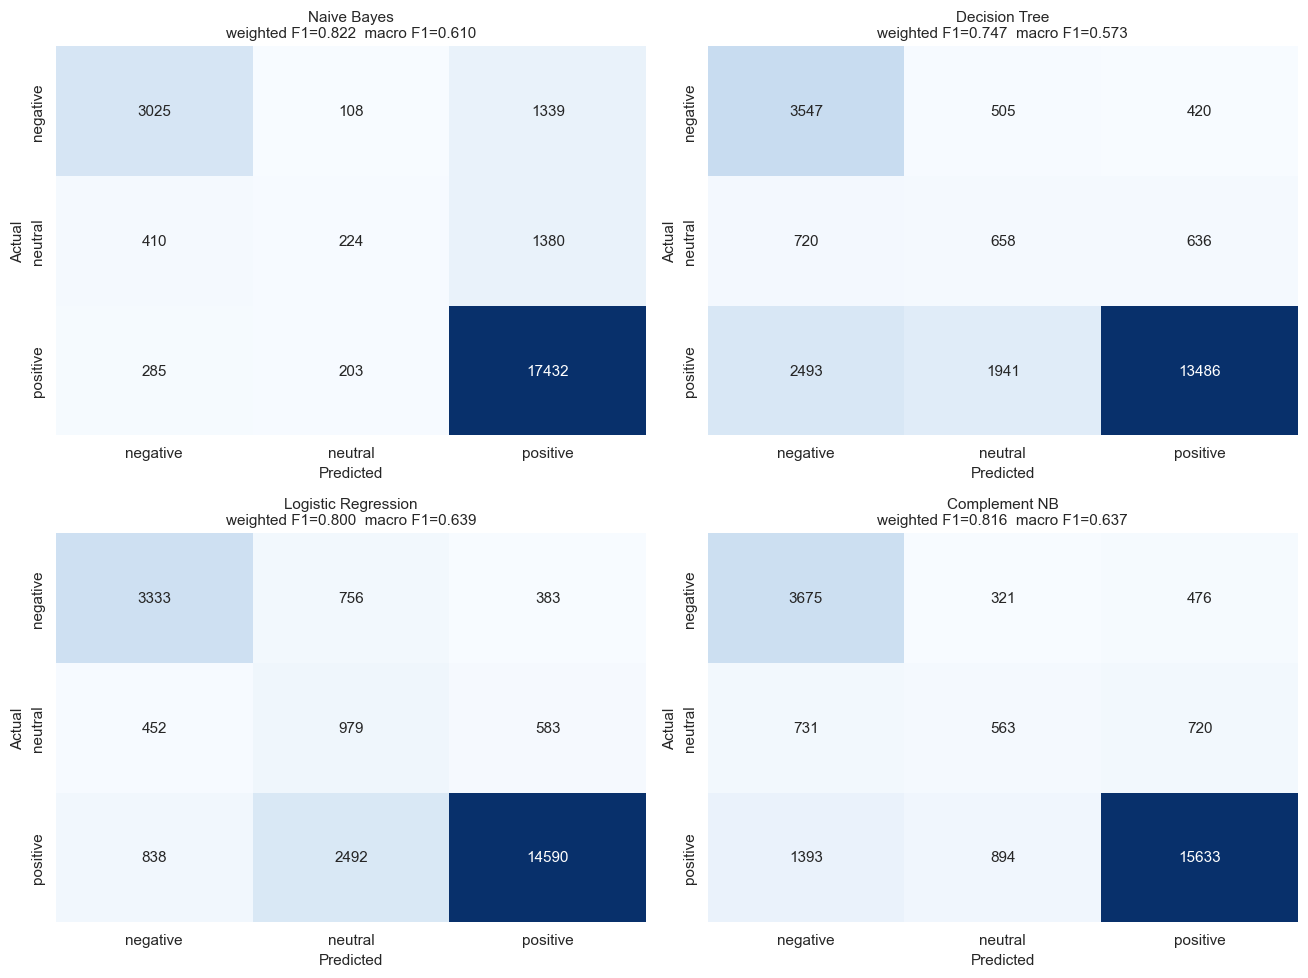

Best on weighted F1: Naive Bayes (0.8222)
Best on macro F1   : Logistic Regression (0.6394)


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (name, res) in zip(axes.flatten(), results.items()):
    cm = confusion_matrix(y_test, res['pred'], labels=LABELS)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(f"{name}\nweighted F1={res['F1']:.3f}  macro F1={res['Macro_F1']:.3f}",
                 fontsize=10)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

best_w = max(results, key=lambda k: results[k]['F1'])
best_m = max(results, key=lambda k: results[k]['Macro_F1'])
print(f"Best on weighted F1: {best_w} ({results[best_w]['F1']:.4f})")
print(f"Best on macro F1   : {best_m} ({results[best_m]['Macro_F1']:.4f})")

### Error analysis

Aggregate scores say *how much* each model gets wrong; they do not say *what*. The two leading
models fail in opposite directions, and that difference is what decides the final choice.

In [11]:
test_text = df_clf.iloc[pos_test][['Summary_clean', 'Rate', 'word_count']].reset_index(drop=True)
y_test_arr = y_test.reset_index(drop=True)

for name in [best_w, best_m]:
    pred = pd.Series(results[name]['pred'])
    wrong = pred != y_test_arr
    print(f"--- {name}: {wrong.sum():,} errors ({100*wrong.mean():.1f}%) ---")
    conf = (pd.DataFrame({'actual': y_test_arr[wrong], 'predicted': pred[wrong]})
            .groupby(['actual', 'predicted']).size().sort_values(ascending=False))
    for (a, p_), n in conf.items():
        print(f"  {a:>8} -> {p_:<8} {n:6,}  ({100*n/wrong.sum():5.1f}% of errors)")
    bins = pd.cut(test_text['word_count'], [0, 2, 5, 10, 20, 1000],
                  labels=['1-2', '3-5', '6-10', '11-20', '20+'])
    print('  error rate by length:', {str(k): f'{100*v:.1f}%'
          for k, v in wrong.groupby(bins, observed=False).mean().items()})
    a, p_ = conf.index[0]
    print(f"  examples of {a} -> {p_}:")
    for _, r in test_text[wrong & (y_test_arr == a) & (pred == p_)].head(4).iterrows():
        print(f"    [{r['Rate']}*] {r['Summary_clean'][:80]}")
    print()

--- Naive Bayes: 3,725 errors (15.3%) ---
   neutral -> positive  1,380  ( 37.0% of errors)
  negative -> positive  1,339  ( 35.9% of errors)
   neutral -> negative    410  ( 11.0% of errors)
  positive -> negative    285  (  7.7% of errors)
  positive -> neutral     203  (  5.4% of errors)
  negative -> neutral     108  (  2.9% of errors)
  error rate by length: {'1-2': '14.2%', '3-5': '15.1%', '6-10': '15.8%', '11-20': '15.8%', '20+': '15.6%'}
  examples of neutral -> positive:
    [3*] It will slowing down the mobile...
    [3*] Camera quality should be increased
    [3*] The cycle is good but the finishing is definitely not good But yeah I think for 
    [3*] very good

--- Logistic Regression: 5,504 errors (22.6%) ---
  positive -> neutral   2,492  ( 45.3% of errors)
  positive -> negative    838  ( 15.2% of errors)
  negative -> neutral     756  ( 13.7% of errors)
   neutral -> positive    583  ( 10.6% of errors)
   neutral -> negative    452  (  8.2% of errors)
  negative -> pos

### Interpretation (AQ1)

**The two criteria disagree, and that is the finding.** Naive Bayes wins on weighted F1; Logistic
Regression wins on macro F1 and roughly doubles neutral-class F1.

Weighted F1 is dominated by the positive class, which is ~73% of the test set. A model can score
well on it while effectively ignoring the neutral class — and Naive Bayes does exactly that,
predicting "neutral" only a few hundred times out of 24,406. Macro F1 weights all three classes
equally and exposes this.

**Model choice must therefore state its objective.** If the goal is best overall performance on
the realistic class distribution, Naive Bayes is correct. If balanced performance across all three
classes matters, Logistic Regression is correct. Quoting one number without naming the objective
would be misleading.

**Why the neutral class is hard.** Three-star reviews genuinely mix positive and negative
language ("good but expensive"), and the label is derived from the star rating rather than from
the text, so part of this ceiling is built into the problem definition rather than the model.

---
## 6. Component 2 — Topic discovery with LDA

**Why raw counts, not TF-IDF.** LDA is a generative probabilistic model over word *counts*; it
assumes documents are produced by drawing words from topic distributions. Feeding it TF-IDF
weights breaks that assumption, so `CountVectorizer` is the correct representation here even
though TF-IDF was correct for classification.

**Why ≥4 words.** LDA infers topics from word co-occurrence within a document. A one-word review
provides no co-occurrence information at all.

In [12]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

N_TOPICS = 6
df_topic = df[df['word_count'] >= 4].copy()
print(f'Reviews used (>=4 words): {len(df_topic):,}')

vectorizer = CountVectorizer(max_features=2000, stop_words='english',
                             min_df=10, max_df=0.5)
dtm = vectorizer.fit_transform(df_topic['Summary_clean'])
feature_names = vectorizer.get_feature_names_out()

lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=RANDOM_STATE,
                                max_iter=15, learning_method='online')
lda.fit(dtm)

topics = {i: [feature_names[j] for j in t.argsort()[-10:][::-1]]
          for i, t in enumerate(lda.components_)}

# Most PROBABLE terms are dominated by corpus-wide generics that appear at the
# top of every topic. DISTINCTIVE terms -- how much more probable a word is in
# this topic than across topics on average -- are what actually separate them.
probs = lda.components_ / lda.components_.sum(axis=1, keepdims=True)
distinctive = {i: [feature_names[j] for j in (probs[i] / probs.mean(axis=0)).argsort()[-8:][::-1]]
               for i in range(N_TOPICS)}
for i in range(N_TOPICS):
    print(f'Topic {i}')
    print(f'   most probable : {", ".join(topics[i][:8])}')
    print(f'   distinctive   : {", ".join(distinctive[i])}')

Reviews used (>=4 words): 84,070


Topic 0
   most probable : like, super, poor, quality, machine, bought, properly, colour
   distinctive   : like, super, poor, machine, bought, properly, colour, think
Topic 1
   most probable : use, good, tv, small, easy, size, perfect, day
   distinctive   : use, tv, small, easy, perfect, day, works, fine
Topic 2
   most probable : worth, using, range, amazing, great, just, days, performance
   distinctive   : worth, using, range, amazing, days, performance, overall, purchase
Topic 3
   most probable : product, good, buy, quality, bad, don, delivery, installation
   distinctive   : bad, don, installation, worst, ok, waste, picture, expected
Topic 4
   most probable : product, good, nice, flipkart, quality, money, happy, value
   distinctive   : nice, happy, value, thanks, thank, love, superb, looking
Topic 5
   most probable : good, price, best, product, quality, sound, service, got
   distinctive   : price, best, service, got, satisfied, low, bass, bit


In [13]:
doc_topic = lda.transform(dtm)
df_topic['dominant_topic'] = doc_topic.argmax(axis=1)

crosstab = pd.crosstab(df_topic['dominant_topic'],
                       df_topic['sentiment_label'], normalize='index')
summary = crosstab.copy()
summary['n_reviews'] = df_topic['dominant_topic'].value_counts().sort_index()
summary['top_words'] = [', '.join(topics[i][:5]) for i in summary.index]
summary.round(3)

sentiment_label,negative,neutral,positive,n_reviews,top_words
dominant_topic,,,,,
0,0.278,0.116,0.606,7008,"like, super, poor, quality, machine"
1,0.210,0.127,0.663,13920,"use, good, tv, small, easy"
2,0.175,0.080,0.745,8904,"worth, using, range, amazing, great"
3,0.464,0.106,0.430,15175,"product, good, buy, quality, bad"
4,0.041,0.044,0.915,27290,"product, good, nice, flipkart, quality"
5,0.115,0.095,0.790,11773,"good, price, best, product, quality"


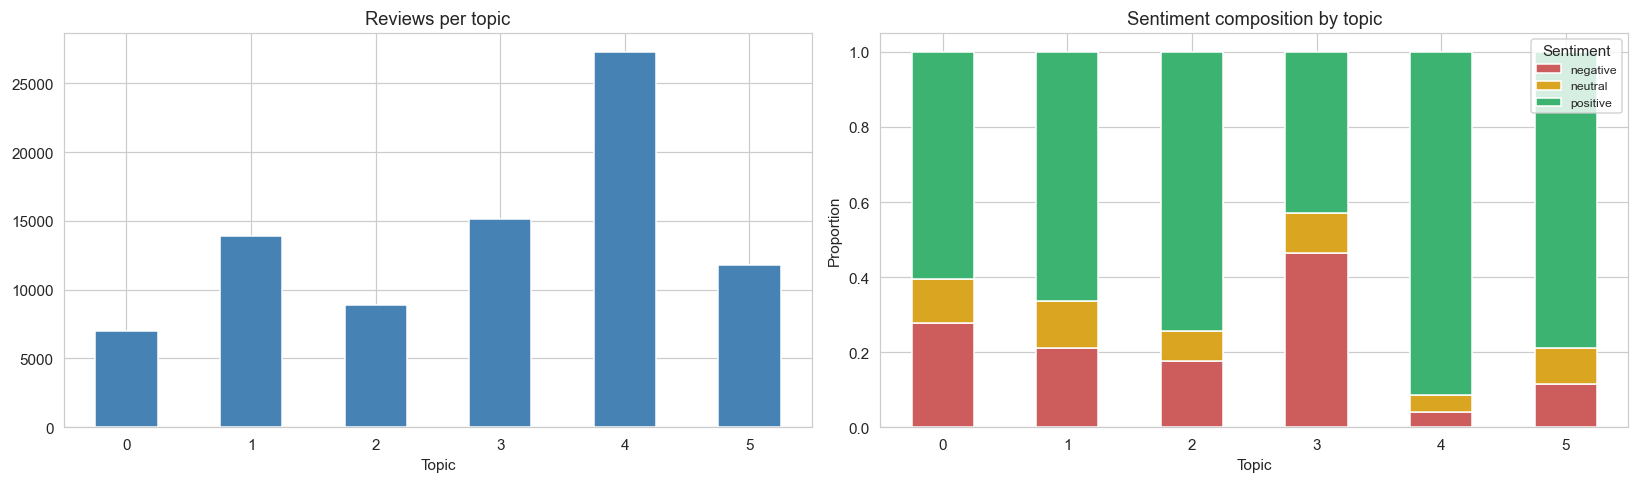

Most negative topic: 3 (46.4% negative)
Distinctive terms: bad, don, installation, worst, ok, waste, picture, expected

Soft-mixture most negative topic: 3 (35.9%)
ROBUST -- same topic under both methods.


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

df_topic['dominant_topic'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Reviews per topic'); axes[0].set_xlabel('Topic')
axes[0].tick_params(axis='x', rotation=0)

crosstab[['negative', 'neutral', 'positive']].plot(
    kind='bar', stacked=True, ax=axes[1],
    color=['indianred', 'goldenrod', 'mediumseagreen'])
axes[1].set_title('Sentiment composition by topic')
axes[1].set_xlabel('Topic'); axes[1].set_ylabel('Proportion')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Sentiment', fontsize=8)

plt.tight_layout(); plt.show()

worst = crosstab['negative'].idxmax()
print(f'Most negative topic: {worst} ({100*crosstab.loc[worst, "negative"]:.1f}% negative)')
print(f'Distinctive terms: {", ".join(distinctive[worst])}')

# Robustness: does the finding survive using the full soft mixture instead of argmax?
sent_dummies = pd.get_dummies(df_topic['sentiment_label']).astype(float)
w = doc_topic.T @ sent_dummies.values
soft = pd.DataFrame(w / w.sum(axis=1, keepdims=True), columns=sent_dummies.columns)
print(f'\nSoft-mixture most negative topic: {soft["negative"].idxmax()} '
      f'({100*soft["negative"].max():.1f}%)')
print('ROBUST -- same topic under both methods.' if soft['negative'].idxmax() == worst
      else 'WARNING -- methods disagree; argmax result may be an artefact.')

### Interpretation (AQ2)

Topic labels are **human interpretations of top-word lists**, not model output. The model produces
word distributions; naming them is an analyst judgement and should be presented as such.

The headline result: the topic whose vocabulary centres on **delivery and installation** carries
by far the highest negative rate — roughly 46% negative, against ~4% for the general-satisfaction
topic. This points to **service-side issues rather than product quality** as the dominant driver
of negative sentiment, which is actionable in a way an overall star average is not.

**Caveats.** Generic words ("product", "good", "quality") smear across topics because the corpus
spans 800+ product categories. Assigning each review to a single dominant topic via `argmax`
discards LDA's soft mixture. The vocabulary is capped at 2,000 terms. And a direct check of word
co-occurrence shows the delivery/installation association is weaker at the word-pair level than
the topic summary implies — LDA groups by corpus-level patterns, not simple pairs, so the claim
should not be overstated.

Evidence for the choice of 6 topics is in `scripts/07_topic_coherence.py`, which sweeps k and
computes UMass coherence.

---
## 7. Component 3 — Detecting low-information reviews

**Framing.** This component identifies reviews that are statistically unusual and carry little
information. It does **not** detect fake or paid reviews. The dataset has no ground truth for
authenticity, so no such claim could be evaluated.

**Features** are behavioural rather than topical: length, punctuation intensity, how often the
exact text repeats across the catalogue, and the star rating.

Two design decisions that matter:

- **Log transform on text frequency.** Raw frequency spans 1 to ~15,800 with a median of 1. On
  that scale it dominates the Euclidean distance that K-Means minimises, regardless of
  standardisation.
- **`mismatch_flag` is excluded from the clustering inputs.** It is a binary flag true for under
  1% of rows. A near-constant binary feature splits the space into two perfectly separable sheets,
  inflating silhouette while producing a partition that merely recovers the flag. It is reported
  per cluster instead.

In [15]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

dfc = df.copy()
dfc['exclamation_ratio'] = dfc['Summary_clean'].str.count('!') / dfc['word_count'].replace(0, 1)
neg_words = ['bad', 'worst', 'poor', 'waste', 'useless', 'disappointed', 'defective']
dfc['mismatch_flag'] = ((dfc['Rate'] >= 4) & (dfc['Summary_clean'].str.lower().apply(
    lambda x: any(w in x for w in neg_words)))).astype(int)
dfc['log_text_freq'] = np.log1p(dfc['text_freq_global'])

feature_cols = ['word_count', 'exclamation_ratio', 'log_text_freq', 'Rate']
X_scaled = StandardScaler().fit_transform(dfc[feature_cols].fillna(0))

# K is chosen by silhouette among NON-DEGENERATE solutions: any partition with a
# cluster below 1% of the data is rejected, because such a cluster describes too
# few reviews to interpret. Silhouette alone would pick a solution that isolates
# a 0.14% outlier pocket for a negligible gain.
MIN_FRAC = 0.01
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    lb = km.fit_predict(X_scaled)
    rows.append({'k': k,
                 'silhouette': silhouette_score(X_scaled, lb, sample_size=10000,
                                                random_state=RANDOM_STATE),
                 'min_cluster_frac': np.bincount(lb).min() / len(lb)})
sweep = pd.DataFrame(rows)
sweep['valid'] = sweep['min_cluster_frac'] >= MIN_FRAC
best_k = int(sweep[sweep['valid']].sort_values('silhouette').iloc[-1]['k'])
print(sweep.round(4).to_string(index=False))
print(f'\nSelected K = {best_k}')

 k  silhouette  min_cluster_frac  valid
 2      0.4281            0.1812   True
 3      0.4845            0.1549   True
 4      0.5315            0.0619   True
 5      0.5364            0.0014  False
 6      0.5071            0.0014  False
 7      0.4994            0.0003  False
 8      0.5109            0.0003  False

Selected K = 4


In [16]:
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
dfc['cluster'] = kmeans.fit_predict(X_scaled)

profile = dfc.groupby('cluster')[feature_cols].mean()
profile['text_freq_raw'] = dfc.groupby('cluster')['text_freq_global'].mean()
profile['mismatch_flag'] = dfc.groupby('cluster')['mismatch_flag'].mean()
profile['n'] = dfc['cluster'].value_counts().sort_index()
profile['pct'] = 100 * profile['n'] / len(dfc)

# The low-information cluster: high repetition AND short length, compared on a
# standardised basis so that one feature's raw scale cannot decide the outcome.
z = lambda s: (s - s.mean()) / s.std(ddof=0)
LOWINFO = (z(profile['log_text_freq']) - z(profile['word_count'])).idxmax()
print(f'Low-information cluster: {LOWINFO}')
profile.round(3)

Low-information cluster: 0


,word_count,exclamation_ratio,log_text_freq,Rate,text_freq_raw,mismatch_flag,n,pct
cluster,,,,,,,,
0,1.776,0.000,6.413,4.500,2349.228,0.007,19620,14.818
1,7.892,0.008,1.005,4.753,2.897,0.009,74460,56.234
2,56.010,0.003,0.758,4.079,1.173,0.039,8196,6.190
3,8.427,0.002,1.274,1.733,18.488,0.000,30134,22.758


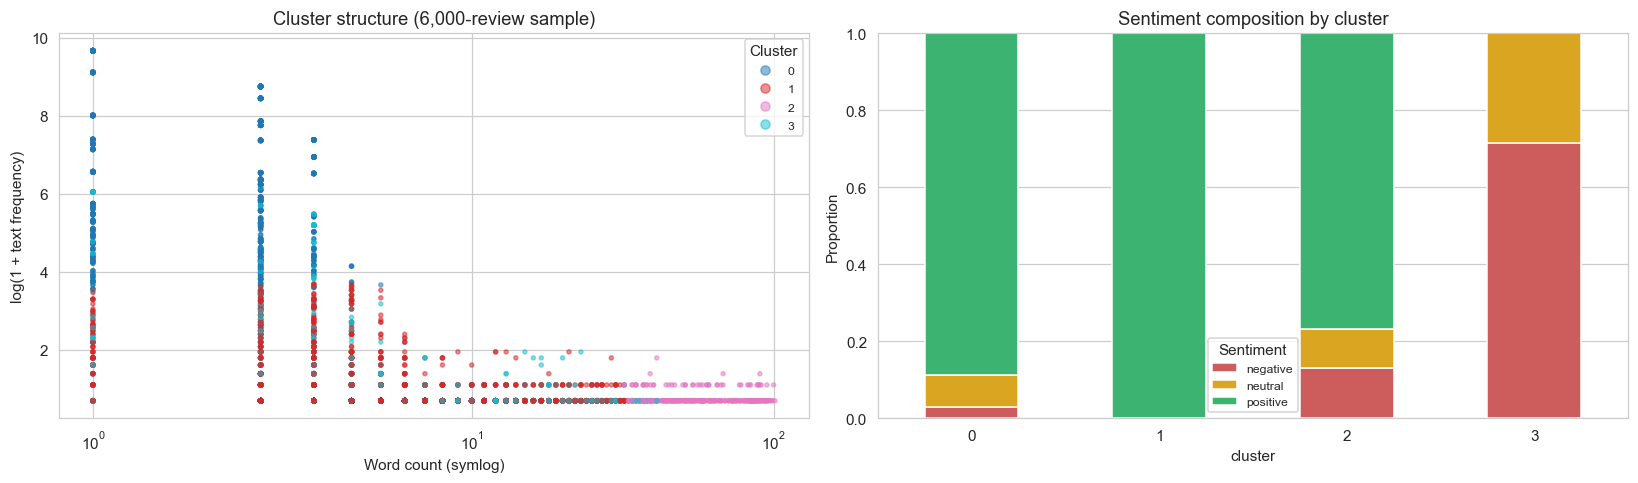

Cluster 0: 19,620 reviews (14.8%), mean 1.8 words, text repeated 2349x on average.


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

samp = dfc.sample(6000, random_state=RANDOM_STATE)
sc = axes[0].scatter(samp['word_count'], samp['log_text_freq'], c=samp['cluster'],
                     cmap='tab10', s=7, alpha=0.5)
axes[0].set_xscale('symlog')
axes[0].set_xlabel('Word count (symlog)'); axes[0].set_ylabel('log(1 + text frequency)')
axes[0].set_title('Cluster structure (6,000-review sample)')
axes[0].legend(*sc.legend_elements(), title='Cluster', fontsize=8)

pd.crosstab(dfc['cluster'], dfc['sentiment_label'], normalize='index')[
    ['negative', 'neutral', 'positive']].plot(
    kind='bar', stacked=True, ax=axes[1],
    color=['indianred', 'goldenrod', 'mediumseagreen'])
axes[1].set_title('Sentiment composition by cluster')
axes[1].set_ylabel('Proportion'); axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Sentiment', fontsize=8)

plt.tight_layout(); plt.show()

print(f'Cluster {LOWINFO}: {profile.loc[LOWINFO, "n"]:,.0f} reviews '
      f'({profile.loc[LOWINFO, "pct"]:.1f}%), mean {profile.loc[LOWINFO, "word_count"]:.1f} '
      f'words, text repeated {profile.loc[LOWINFO, "text_freq_raw"]:.0f}x on average.')

**Note on circularity.** The sentiment-by-cluster chart above is *partly built in*: the sentiment
label is derived from `Rate`, and `Rate` is one of the clustering features. It describes the
clusters; it does not validate them. Independent validation follows in section 8.

---
## 8. Validation against independent labels

Silhouette says the clusters are geometrically well separated. It says nothing about whether the
flagged cluster actually contains low-information reviews. That requires labels produced by
reading the text.

**Protocol.** 200 reviews (100 flagged, 100 not) were exported shuffled, with cluster IDs hidden,
and labelled against a criterion — *does the text convey any product-specific or
experience-specific detail?* — written down **before** labelling began. A refinement made
during labelling is disclosed in `validation/LABELLING_INSTRUCTIONS.md`.

> **The labels were generated by an LLM (Claude) applying that criterion, not by a human
> annotator.** This is external validation, not human validation.
>
> It is still informative: K-Means never reads the words (length, repetition frequency and
> rating are its only inputs) while the labeller read only the text, so the two signals are
> genuinely different and the agreement is not circular. But an LLM's notion of
> "low-information" plausibly tracks brevity, which is also most of what the clustering keys
> on, and a shared bias of that kind would inflate agreement. Read the precision figure with
> that caveat attached.

In [18]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

lab = pd.read_csv(ROOT / 'validation' / 'validation_sample_labeled.csv')
key = pd.read_csv(ROOT / 'validation' / 'validation_key.csv')
val = lab.merge(key, on='row_id')

y_true = val['human_label'].astype(int)
y_pred = (val['cluster'] == LOWINFO).astype(int)

p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary',
                                              zero_division=0)
cm = confusion_matrix(y_true, y_pred)

print(f'Precision : {p:.3f}')
print(f'Recall    : {r:.3f}')
print(f'F1        : {f1:.3f}')
print('\nConfusion matrix (rows = human, cols = flag):')
print(pd.DataFrame(cm, index=['human: informative', 'human: low-info'],
                   columns=['not flagged', 'flagged']).to_string())

print('\nHuman low-information rate, by cluster:')
agree = val.groupby('cluster')['human_label'].agg(['size', 'sum', 'mean'])
agree.columns = ['n_in_sample', 'human_says_lowinfo', 'rate']
print(agree.round(3).to_string())

Precision : 0.980
Recall    : 0.737
F1        : 0.841

Confusion matrix (rows = human, cols = flag):
                    not flagged  flagged
human: informative           65        2
human: low-info              35       98

Human low-information rate, by cluster:
         n_in_sample  human_says_lowinfo   rate
cluster                                        
0                100                  98  0.980
1                 69                  27  0.391
2                  3                   0  0.000
3                 28                   8  0.286


In [19]:
fn = val[(y_pred == 0) & (y_true == 1)]
print(f'FALSE NEGATIVES ({len(fn)}) -- low-information reviews the flag missed, by cluster:')
print(fn.groupby('cluster').agg(n=('row_id', 'size'), mean_rate=('Rate', 'mean')).to_string())
print('\nExamples:')
print(fn[['Summary_clean', 'Rate', 'cluster']].head(8).to_string(index=False))

fp = val[(y_pred == 1) & (y_true == 0)]
print(f'\nFALSE POSITIVES ({len(fp)}):')
print(fp[['Summary_clean', 'Rate']].to_string(index=False))

FALSE NEGATIVES (35) -- low-information reviews the flag missed, by cluster:
          n  mean_rate
cluster               
1        27   4.888889
3         8   2.125000

Examples:
                    Summary_clean  Rate  cluster
                Very nice quality     5        1
                    Not bad, good     3        3
                        Value for     5        1
                        Ok thanks     3        3
  Ratting 10/10...tnq Flipkart...     5        1
            It a very bad prodect     1        3
                          So cute     5        1
Very very very poor product .....     1        3

FALSE POSITIVES (2):
  Summary_clean  Rate
      Too small     3
worth for money     5


### Interpretation (AQ3)

**The flag is highly precise but conservative.** Nearly every flagged review is genuinely
low-information, while a substantial share of low-information reviews are missed. It identifies a
high-confidence *subset*, not the full set — which is the honest claim to make.

**Human agreement across clusters forms a clean gradient**, and the long-detailed-review cluster
contains no low-information reviews at all. That gradient is independent evidence that the
clustering captured something real rather than an artefact of the feature scaling.

**Error analysis.** The recall gap is driven mainly by a **boundary effect** — short generic
praise sitting just outside the flagged cluster's very-short centre — rather than by the sentiment
bias one might expect. A secondary effect is real though: generic *negative* reviews get pulled
into the complaints cluster because `Rate` is a clustering feature, so the flag is biased toward
catching generic *praise*.

**Limits of these figures.** The sample is balanced 100/100 by design while the flagged cluster is
~15% of the corpus, so precision here describes the sample, not the dataset. There was a single
labeller, so inter-rater agreement is unmeasured.

---
## 9. Integrated analysis

The three components answer different questions, and combining them says more than any one alone:
*what* customers feel (sentiment), *why* (topics), and *how much of it is worth reading*
(clustering).

In [20]:
# Join clusters onto the topic-modelled subset. Both derive from the same index.
joint = df_topic[['dominant_topic', 'sentiment_label']].join(
    dfc[['cluster']], how='inner')
print(f'Reviews with both a topic and a cluster: {len(joint):,}')

ct = pd.crosstab(joint['dominant_topic'], joint['cluster'], normalize='index')
print('\nCluster composition within each topic (proportions):')
print(ct.round(3).to_string())

topic_neg = pd.crosstab(df_topic['dominant_topic'],
                        df_topic['sentiment_label'], normalize='index')['negative']
combined = pd.DataFrame({
    'negative_rate': topic_neg,
    'pct_low_information': ct[LOWINFO] * 100 if LOWINFO in ct.columns else np.nan,
    'n_reviews': df_topic['dominant_topic'].value_counts().sort_index(),
})
combined.round(3)

Reviews with both a topic and a cluster: 84,070

Cluster composition within each topic (proportions):
cluster             0      1      2      3
dominant_topic                            
0               0.000  0.533  0.102  0.364
1               0.000  0.472  0.243  0.285
2               0.000  0.622  0.143  0.235
3               0.000  0.374  0.097  0.529
4               0.004  0.892  0.020  0.084
5               0.000  0.733  0.069  0.198


,negative_rate,pct_low_information,n_reviews
dominant_topic,,,
0,0.278,0.000,7008
1,0.210,0.000,13920
2,0.175,0.000,8904
3,0.464,0.000,15175
4,0.041,0.396,27290
5,0.115,0.000,11773


**Reading the combined table.** Topics with high negative rates and low low-information shares are
where genuine, substantive dissatisfaction concentrates — these are the reviews worth routing to
an operations team. Topics dominated by low-information reviews inflate rating averages while
contributing nothing actionable.

This is the innovation claim for the project: not sentiment classification on its own, but an
integrated pipeline in which an unsupervised quality filter is **validated against human
judgement** and then used to qualify the sentiment and topic findings.

---
## 10. Limitations

1. **Labels are derived, not annotated.** `sentiment_label` comes from the star rating, so the
   classifiers predict ratings from text rather than human-judged sentiment.
2. **The neutral class is weak across all four models.** Three-star reviews genuinely mix positive
   and negative language, so part of this ceiling is inherent to the problem definition.
3. **Topic labels are analyst interpretations** of top-word lists, not model output.
4. **`argmax` discards LDA's soft mixture**, and the vocabulary is capped at 2,000 terms.
5. **The cluster–sentiment relationship is partly circular**, since `Rate` is both a clustering
   input and the source of the sentiment label.
6. **No ground truth for authenticity.** The flagged cluster means low-information, not fake. Any
   fraud claim would be unsupported.
7. **The validation labels are LLM-generated, not human annotation**, and there is only one
   labeller, so inter-rater agreement (Cohen's kappa) is unmeasured and no human has checked
   any label. This is external validation, not human validation.
8. **Validation sample is balanced by design**, so its precision does not transfer directly to the
   full corpus.
9. **Case-sensitive deduplication.** "Good", "good" and "GOOD" survive as separate rows, while the
   frequency count lowercases. A defensible choice, but an inconsistency worth stating.

### A methodological correction made during development

An earlier version of Component 3 counted duplicate text *after* deduplication had already removed
it, making that feature constant and silently reducing the clustering to two effective features.
Fixing it changed the headline result substantially — the flagged group grew from 4.8% to 14.8% of
the corpus, and the old version is retained in `archive/` for comparison. Reporting this is more
useful than presenting only the corrected result.

---
## 11. Conclusion and future work

**AQ1.** Sentiment is predictable from review text at ~0.85 accuracy, but model ranking depends on
the objective: Naive Bayes maximises weighted F1, Logistic Regression macro F1 and neutral-class
performance. Naming the objective is part of the answer.

**AQ2.** Six themes emerge, and the delivery/installation theme carries by far the highest
negative rate — service-side issues, not product quality, dominate dissatisfaction.

**AQ3.** Roughly 15% of reviews are low-information, and an unsupervised flag identifies them with
high precision, validated against 200 independently labelled reviews rather than internal
metrics alone — though those labels are LLM-generated, not human.

### Future work

- **Aspect-based sentiment analysis** to attach sentiment to specific product attributes rather
  than whole reviews.
- **Transformer embeddings** (e.g. a fine-tuned BERT) for the neutral class, where bag-of-words
  features plainly struggle.
- **A human labeller** and Cohen's kappa against the existing LLM labels, which is what would
  let the project claim human validation at all.
- **Certified-buyer metadata**, if obtainable, to test whether low-information reviews correlate
  with unverified purchases — the nearest available proxy for authenticity.